In [1]:
import naima
from naima.models import ExponentialCutoffPowerLaw
import astropy.units as u
from astropy.constants import c
import numpy as np
import matplotlib.pyplot as plt

### Define distribution of non-thermal electrons

In [2]:
#from astropy.io import ascii
#data = ascii.read('/home/fglsma/Dropbox/Trabajo/Investigacion/eht_garra/ExtendedJet/Example_sync_code/data/data2.ecsv')
#energies = data.columns.get('energy') / eV
#energies = np.asarray(energies.tolist())
dist_compare= np.loadtxt("/home/fglsma/Dropbox/Trabajo/Investigacion/eht_garra/ExtendedJet/Example_sync_code/dist_e.dat")

In [3]:
eV=1.602176E-12
e_0=1*u.eV
e_break=1E100*u.eV
alpha_1=2
amplitude = 1.7690615972392788E+043*np.power(eV,-alpha_1)
alpha_2=0
e_cutoff=1.E13*u.eV
beta=1

Q = naima.models.ExponentialCutoffBrokenPowerLaw( amplitude=amplitude*u.Unit('1/eV'), \
                                                 e_0=e_0, \
                                                 e_break=e_break, \
                                                 alpha_1=alpha_1, \
                                                 alpha_2 = alpha_2, \
                                                 e_cutoff=e_cutoff, \
                                                 beta=1)
Q_eval = Q.eval(amplitude=amplitude*u.Unit('1/eV'), \
                e=dist_compare[:,0]*u.eV, \
                e_0=e_0, \
                e_break=e_break, \
                alpha_1=alpha_1, \
                alpha_2=alpha_2, \
                e_cutoff=e_cutoff, \
                beta=1)

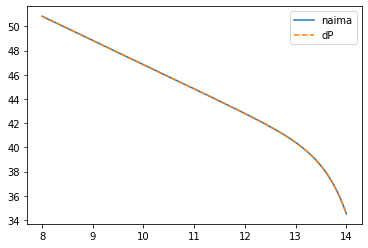

In [4]:
plt.plot( np.log10(dist_compare[:,0]), np.log10(Q_eval/u.Unit('1/eV')), label="naima")
plt.plot( np.log10(dist_compare[:,0]), np.log10(dist_compare[:,1]), '--', label="dP")
plt.legend()

### Synchrotron emission

In [5]:
sed_compare= np.loadtxt("/home/fglsma/Dropbox/Trabajo/Investigacion/eht_garra/ExtendedJet/Example_sync_code/radsyn.dat")
# sed_compare[:,0] are the photon energies [eV]
# sed_compare[:,1] are the luminosities per unit of energy [erg/s/erg]
sed_compare_energy_erg = sed_compare[:,0] * u.eV.to(u.erg,1) * u.erg / u.eV
sed_compare_energy_eV = sed_compare[:,0]*u.eV

In [6]:
# Convert sed_compare[:,1] to units of erg/s/cm^2
sed_compare[:,1] = sed_compare[:,0] * sed_compare[:,1] / (u.second * 4*np.pi*(u.kpc.to(u.cm,1)*u.cm)**2)

In [7]:
# Get naima sed
B = 1E-2*u.G
distance = 1*u.kpc
Eemin=1e8*u.eV
SYN = naima.models.Synchrotron(Q, B=B, Eemin=Eemin)
sed_SYN = SYN.sed(sed_compare[:,0]*u.eV, distance=distance) # erg/s/cm^2

In [8]:
#plt.plot( np.log10(sed_compare_energy_eV/u.eV), np.log10( (sed_SYN/sed_compare_energy_erg) * u.second * u.centimeter * u.centimeter ))

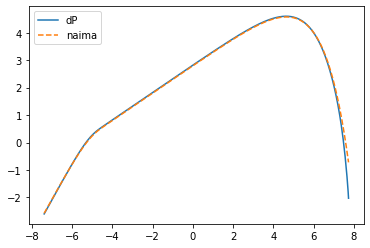

In [9]:
plt.plot( np.log10(sed_compare_energy_eV/u.eV), np.log10( sed_compare[:,1]), label='dP')
plt.plot( np.log10(sed_compare_energy_eV/u.eV), np.log10( sed_SYN * u.cm*u.cm*u.second / (u.erg )), '--', label='naima')
plt.legend()

### SSC emision

In [10]:
sed_compare_ssc = np.loadtxt("/home/fglsma/Dropbox/Trabajo/Investigacion/eht_garra/ExtendedJet/Example_sync_code/radssc.dat")
# sed_compare[:,0] are the photon energies [eV]
# sed_compare[:,1] are the luminosities per unit of energy [erg/s/erg]
sed_compare_ssc_energy_eV = sed_compare_ssc[:,0]*u.eV

In [11]:
# Convert sed_compare[:,1] to units of erg/s/cm^2
sed_compare_ssc[:,1] = sed_compare_ssc[:,0] * sed_compare_ssc[:,1] / (u.second * 4*np.pi*(u.kpc.to(u.cm,1)*u.cm)**2)

In [36]:
sed_compare_ssc[1,1]

2.0984126494155947e-05

In [12]:
Lsy = SYN.flux(sed_compare[:,0]*u.eV, distance=0*u.cm) # 1/eV/s

<Quantity [1.15512664e+68, 1.12143097e+68, 1.08869950e+68, 1.05690463e+68,
           1.02601955e+68, 9.96018232e+67, 9.66875376e+67, 9.38566415e+67,
           9.11067484e+67, 8.84355402e+67, 8.58407654e+67, 8.33202368e+67,
           8.08718298e+67, 7.84934810e+67, 7.61831858e+67, 7.39389973e+67,
           7.17590242e+67, 6.96414295e+67, 6.75844289e+67, 6.55862890e+67,
           6.36453263e+67, 6.17599056e+67, 5.99284384e+67, 5.81493818e+67,
           5.64212372e+67, 5.47425487e+67, 5.31119026e+67, 5.15279252e+67,
           4.99892825e+67, 4.84946789e+67, 4.70428555e+67, 4.56325898e+67,
           4.42626943e+67, 4.29320156e+67, 4.16394333e+67, 4.03838592e+67,
           3.91642363e+67, 3.79795378e+67, 3.68287666e+67, 3.57109540e+67,
           3.46251592e+67, 3.35704683e+67, 3.25459939e+67, 3.15508737e+67,
           3.05842705e+67, 2.96453708e+67, 2.87333849e+67, 2.78475453e+67,
           2.69871070e+67, 2.61513461e+67, 2.53395597e+67, 2.45510649e+67,
           2.37851988e+67

In [45]:
R = 0.01 *  u.pc
#c = 2.99792458e10 * u.cm / u.second
phn_sy = Lsy / (4 * np.pi * R**2 * c) * 2.24

In [46]:
phn_sy

<Quantity [6.86826513e+60, 6.66791411e+60, 6.47329611e+60, 6.28424706e+60,
           6.10060755e+60, 5.92222277e+60, 5.74894232e+60, 5.58062013e+60,
           5.41711429e+60, 5.25828698e+60, 5.10400431e+60, 4.95413625e+60,
           4.80855647e+60, 4.66714228e+60, 4.52977449e+60, 4.39633733e+60,
           4.26671835e+60, 4.14080833e+60, 4.01850117e+60, 3.89969381e+60,
           3.78428616e+60, 3.67218097e+60, 3.56328380e+60, 3.45750291e+60,
           3.35474919e+60, 3.25493609e+60, 3.15797953e+60, 3.06379785e+60,
           2.97231173e+60, 2.88344412e+60, 2.79712018e+60, 2.71326722e+60,
           2.63181464e+60, 2.55269384e+60, 2.47583821e+60, 2.40118306e+60,
           2.32866552e+60, 2.25822456e+60, 2.18980088e+60, 2.12333688e+60,
           2.05877663e+60, 1.99606579e+60, 1.93515158e+60, 1.87598275e+60,
           1.81850951e+60, 1.76268350e+60, 1.70845774e+60, 1.65578663e+60,
           1.60462584e+60, 1.55493235e+60, 1.50666436e+60, 1.45978127e+60,
           1.41424365e+60

In [47]:
IC = naima.models.InverseCompton(Q, seed_photon_fields=[['SSC', sed_compare[:,0]*u.eV, phn_sy]])
sed_IC = IC.sed(sed_compare_ssc_energy_eV, distance=distance)

In [48]:
distance

<Quantity 1. kpc>

/usr/lib/python3/dist-packages/ipykernel_launcher.py:1: RuntimeWarning: divide by zero encountered in log10
  """Entry point for launching an IPython kernel.


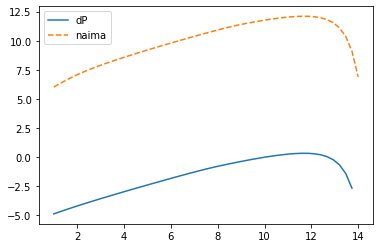

In [49]:
plt.plot( np.log10(sed_compare_ssc_energy_eV/u.eV), np.log10( sed_compare_ssc[:,1]), label='dP')
plt.plot( np.log10(sed_compare_ssc_energy_eV/u.eV), np.log10( sed_IC * u.cm*u.cm*u.second / (u.erg )), '--', label='naima')
plt.legend()

/usr/lib/python3/dist-packages/ipykernel_launcher.py:3: RuntimeWarning: divide by zero encountered in log10
  This is separate from the ipykernel package so we can avoid doing imports until


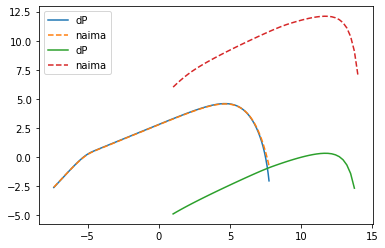

In [50]:
plt.plot( np.log10(sed_compare_energy_eV/u.eV), np.log10( sed_compare[:,1]), label='dP')
plt.plot( np.log10(sed_compare_energy_eV/u.eV), np.log10( sed_SYN * u.cm*u.cm*u.second / (u.erg )), '--', label='naima')
plt.plot( np.log10(sed_compare_ssc_energy_eV/u.eV), np.log10( sed_compare_ssc[:,1]), label='dP')
plt.plot( np.log10(sed_compare_ssc_energy_eV/u.eV), np.log10( sed_IC * u.cm*u.cm*u.second / (u.erg )), '--', label='naima')
plt.legend()